Next, enter predict.py to validate the network training.
Same as training, the initial section of the code imports essential libraries.

In [1]:
import os
import json

import torch
from PIL import Image
from torchvision import transforms
import matplotlib.pyplot as plt
import pandas as pd
from model import MLP

# Here we could import the library

ModuleNotFoundError: No module named 'torch'

This section of the code handles device configuration and data loading for the MLP (Multilayer Perceptron) network. It involves setting up the device for computation and importing data from an Excel file.

In [ ]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

excel_file = 'nfet_ids_vds.xlsx'
df = pd.read_excel(excel_file)
df.head()

,vds,vgs,lg,ids
0,0.00,0.0,0.25,-2.120430e-10
1,0.02,0.0,0.25,3.188530e-08
2,0.04,0.0,0.25,5.823670e-08
3,0.06,0.0,0.25,8.871480e-08
4,0.08,0.0,0.25,1.089610e-07


Extract input and output columns

In [ ]:
# Extract input and output columns
input_columns = ['vds', 'vgs','lg']
output_column = 'ids'

Converts the selected input columns and output column into PyTorch tensors.

In [ ]:
X = torch.tensor(df[input_columns].values, dtype=torch.float32)
Y = torch.tensor(df[output_column].values, dtype=torch.float32)

Initializes an instance of the MLP model (MLP()) and assigns it to the defined computational device (device).

In [ ]:
# create model
model = MLP().to(device)

This section of the code is responsible for loading pre-existing weights into the previously instantiated MLP model.
model.load_state_dict(torch.load(weights_path)): Utilizes PyTorch's load_state_dict() method to load the pretrained weights into the MLP model.

In [ ]:
# load model weights
weights_path = "./MLP.pth"
assert os.path.exists(weights_path), "file: '{}' dose not exist.".format(weights_path)
model.load_state_dict(torch.load(weights_path))

C:\Users\Lava\AppData\Local\Temp\ipykernel_21676\2977053959.py:4: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(weights_path))


<All keys matched successfully>

This section of the code executes model predictions and applies transformations to the predictions obtained from the MLP model.
predict = model(X.to(device)).cpu(): Performs predictions using the MLP model (model) on the input data (X).
predict_e = -1 * torch.exp(-10*predict): Applies a transformation to the predicted outputs (predict) using exponential functions.

In [ ]:
# model.eval()
with torch.no_grad():
    predict = model(X.to(device)).cpu()
    predict_e =  torch.exp(-10*predict)

    print(predict)
    print(predict_e)

tensor([2.2531, 1.7429, 1.6526,  ..., 0.8076, 0.8088, 0.8101])
tensor([1.6401e-10, 2.6946e-08, 6.6536e-08,  ..., 3.1085e-04, 3.0706e-04,
        3.0332e-04])


Plot the actual and predicted I-V curves to see how the fit between the MLP model predicted values and the actual data values is.
The three subgraphs drawn here are the Ids-Vds curves of pfet under different process parameters.

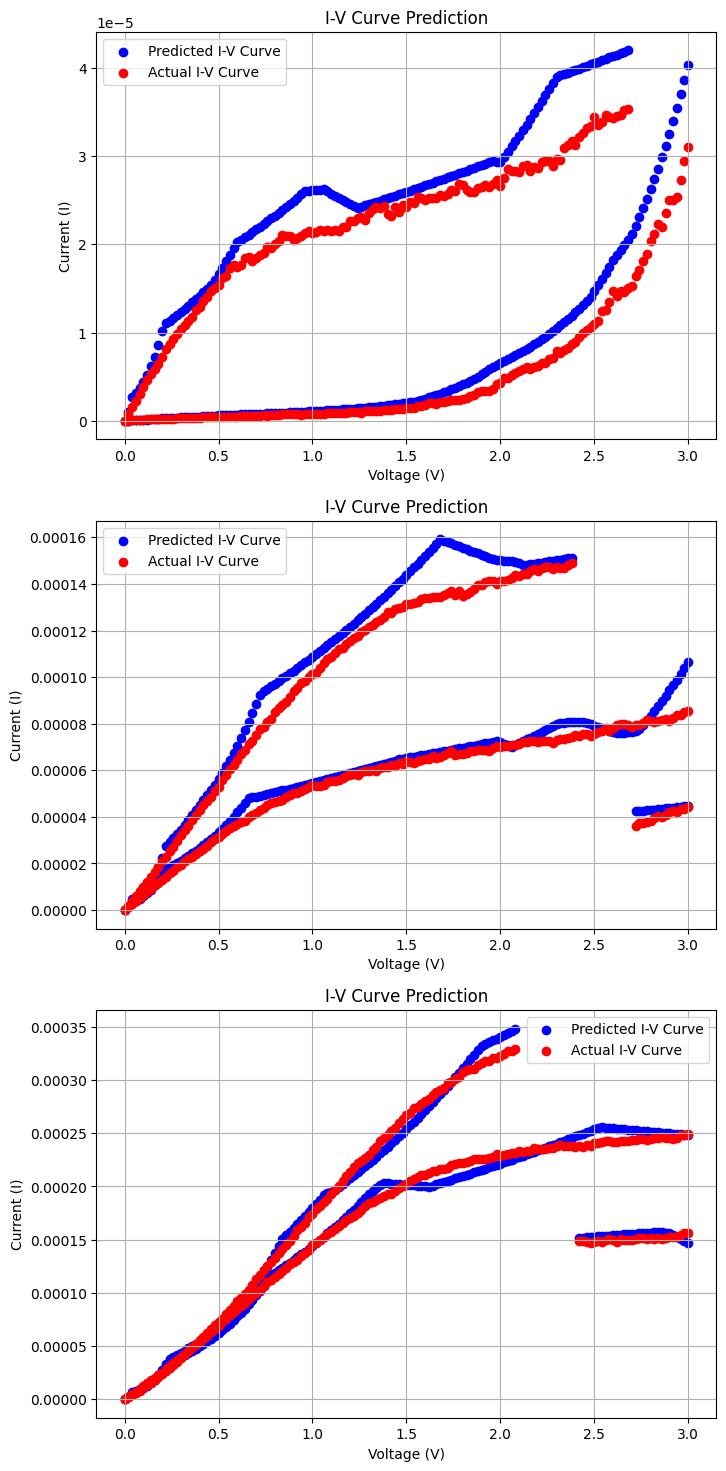

In [ ]:
plt.figure(figsize=(8, 18))

# The difference of these three pictures are mainly different process parameters
plt.subplot(3, 1, 1)   # 3 rows and 1 column, 1st sub-picture
plt.scatter(X[0:286, 0].numpy(), predict_e[0:286].numpy(), label='Predicted I-V Curve', color='blue', linewidth=1)
plt.scatter(X[0:286, 0].numpy(), Y[0:286].numpy(), label='Actual I-V Curve', color='red', linewidth=1)

plt.xlabel('Voltage (V)')
plt.ylabel('Current (I)')
plt.title('I-V Curve Prediction')
plt.legend()
plt.grid(True)

plt.subplot(3, 1, 2) # 3 rows and 1 column, 2nd sub-picture
plt.scatter(X[287:573, 0].numpy(), predict_e[287:573].numpy(), label='Predicted I-V Curve', color='blue', linewidth=1)
plt.scatter(X[287:573, 0].numpy(), Y[287:573].numpy(), label='Actual I-V Curve', color='red', linewidth=1)
plt.xlabel('Voltage (V)')
plt.ylabel('Current (I)')
plt.title('I-V Curve Prediction')
plt.legend()
plt.grid(True)

plt.subplot(3, 1, 3)# 3 rows and 1 column, 3rd sub-picture
plt.scatter(X[574:860, 0].numpy(), predict_e[574:860].numpy(), label='Predicted I-V Curve', color='blue',
            linewidth=1)
plt.scatter(X[574:860, 0].numpy(), Y[574:860].numpy(), label='Actual I-V Curve', color='red', linewidth=1)
plt.xlabel('Voltage (V)')
plt.ylabel('Current (I)')
plt.title('I-V Curve Prediction')
plt.legend()
plt.grid(True)

plt.show()